# Временные ряды. Домашнее задание 1

Прогноз средних месячных температур Португалии по данным Berkeley Earth: подготовка ряда, разбиение на train и test, скользящее окно, признаки, линейная регрессия и оценка прогноза метриками MAE, RMSE и MAPE.

## 1. Подготовка данных

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error

plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#52514e',
    'axes.titlecolor': '#0b0b0b',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#f0efec',
    'xtick.color': '#52514e',
    'ytick.color': '#52514e',
    'legend.frameon': False,
})

BLUE = '#2a78d6'
ORANGE = '#eb6834'

df = pd.read_csv('../homework_data/GlobalLandTemperaturesByCountry.csv')
portugal = df[df['Country'] == 'Portugal'].copy()
print(portugal.shape)

(3129, 4)


In [2]:
portugal['dt'] = pd.to_datetime(portugal['dt'])
portugal = portugal.set_index('dt').sort_index()
full_series = portugal['AverageTemperature']
print(full_series.index.min(), full_series.index.max())

1753-01-01 00:00:00 2013-09-01 00:00:00


In [3]:
print('Пропусков во всём ряду:', full_series.isna().sum())
print('Даты пропусков:', full_series.index[full_series.isna()].strftime('%Y-%m').tolist())

uncertainty = portugal['AverageTemperatureUncertainty']
print('Средняя неопределённость до 1900 года:', round(uncertainty.loc[:'1899-12'].mean(), 3))
print('Средняя неопределённость с 1900 года:', round(uncertainty.loc['1900-01':].mean(), 3))

series = full_series.loc['1900-01':].dropna().asfreq('MS')
print('Наблюдений:', len(series))
print('Период:', series.index.min().strftime('%Y-%m'), series.index.max().strftime('%Y-%m'))
print('Частота:', series.index.freq)
print('Пропусков после обработки:', series.isna().sum())
print('Индекс возрастает:', series.index.is_monotonic_increasing)

Пропусков во всём ряду: 1
Даты пропусков: ['2013-09']
Средняя неопределённость до 1900 года: 2.264
Средняя неопределённость с 1900 года: 0.392
Наблюдений: 1364
Период: 1900-01 2013-08
Частота: <MonthBegin>
Пропусков после обработки: 0
Индекс возрастает: True


Скользящее среднее, минимум: 13.66
Скользящее среднее, максимум: 16.4


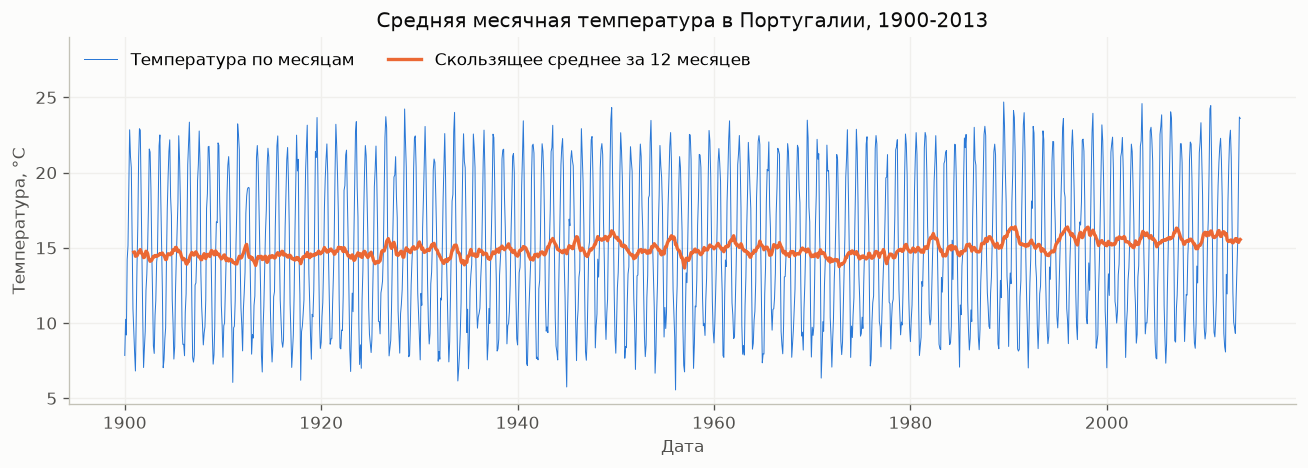

In [4]:
rolling_mean = series.rolling(12).mean()
print('Скользящее среднее, минимум:', round(rolling_mean.min(), 2))
print('Скользящее среднее, максимум:', round(rolling_mean.max(), 2))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(series.index, series, color=BLUE, linewidth=0.6, label='Температура по месяцам')
ax.plot(rolling_mean.index, rolling_mean, color=ORANGE, linewidth=2, label='Скользящее среднее за 12 месяцев')
ax.set_title('Средняя месячная температура в Португалии, 1900-2013')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.set_ylim(top=29)
ax.legend(loc='upper left', ncols=2)
fig.tight_layout()
plt.show()

**Вывод.** Ряд идёт с 1900-01 по 2013-08: 1364 месяца с месячной частотой и без пропусков, единственный пропуск 2013-09 стоял в конце и отсечён. Ранние годы отброшены из-за большой неопределённости измерений (в среднем 2.264 °C до 1900 года против 0.392 °C после), а на графике видна устойчивая годовая сезонность при скользящем среднем от 13.66 до 16.4 °C.

## 2. Holdout-разбиение

In [5]:
split_point = int(len(series) * 0.8)
train = series.iloc[:split_point]
test = series.iloc[split_point:]

assert train.index.max() < test.index.min()

print('Размеры:', len(train), len(test))
print('Доли:', round(len(train) / len(series), 3), round(len(test) / len(series), 3))
print('Train:', train.index.min().strftime('%Y-%m'), train.index.max().strftime('%Y-%m'))
print('Test:', test.index.min().strftime('%Y-%m'), test.index.max().strftime('%Y-%m'))

Размеры: 1091 273
Доли: 0.8 0.2
Train: 1900-01 1990-11
Test: 1990-12 2013-08


**Вывод.** Train занял 1091 месяц до 1990-11, test 273 месяца с 1990-12, доли 0.8 и 0.2. Порядок времени сохранён: все наблюдения test идут после train.

## 3. Скользящее окно

In [6]:
def rolling_window_splits(series, train_size=120, horizon=12, step=12):
    splits = []
    for start in range(0, len(series) - train_size - horizon + 1, step):
        train_idx = np.arange(start, start + train_size)
        test_idx = np.arange(start + train_size, start + train_size + horizon)
        splits.append((train_idx, test_idx))
    return splits


splits = rolling_window_splits(train)
print('Число сплитов:', len(splits))

pd.DataFrame([
    {
        'сплит': number,
        'начало обучения': train.index[train_idx[0]].strftime('%Y-%m'),
        'конец обучения': train.index[train_idx[-1]].strftime('%Y-%m'),
        'начало прогноза': train.index[test_idx[0]].strftime('%Y-%m'),
        'конец прогноза': train.index[test_idx[-1]].strftime('%Y-%m'),
    }
    for number, (train_idx, test_idx) in enumerate(splits[:2], start=1)
])

Число сплитов: 80


,сплит,начало обучения,конец обучения,начало прогноза,конец прогноза
0,1,1900-01,1909-12,1910-01,1910-12
1,2,1901-01,1910-12,1911-01,1911-12


In [7]:
assert all(len(train_idx) == 120 and len(test_idx) == 12 for train_idx, test_idx in splits)
assert all(test_idx[0] == train_idx[-1] + 1 for train_idx, test_idx in splits)
assert all(len(np.intersect1d(train_idx, test_idx)) == 0 for train_idx, test_idx in splits)
assert splits[-1][1][-1] < len(train)
print('Длины окон, порядок и отсутствие пересечений подтверждены для всех сплитов')

Длины окон, порядок и отсутствие пересечений подтверждены для всех сплитов


**Вывод.** Скользящее окно на train дало 80 сплитов по 120 месяцев обучения и 12 месяцев прогноза с шагом 12. Test в этих сплитах не участвует, а прогнозный отрезок начинается сразу за обучением и с ним не пересекается.

## 4. Генерация признаков

In [8]:
features = pd.DataFrame({'temperature': series})
features['lag_1'] = series.shift(1)
features['lag_12'] = series.shift(12)
features['month'] = features.index.month
features['is_winter'] = features.index.month.isin([12, 1, 2]).astype(int)

print(features.shape)
print(features.columns.tolist())

(1364, 5)
['temperature', 'lag_1', 'lag_12', 'month', 'is_winter']


**Вывод.** В таблице признаков 1364 строки и 5 столбцов: температура, два лага, номер месяца и индикатор зимы. Лаги берут только прошлые значения, поэтому у первых 12 месяцев lag_12 пуст, и в модель они не попадают.

## 5. Моделирование и прогноз

In [9]:
feature_columns = ['lag_1', 'lag_12', 'month', 'is_winter']
model_data = features.dropna()

train_data = model_data[model_data.index.isin(train.index)]
test_data = model_data[model_data.index.isin(test.index)]

X_train, y_train = train_data[feature_columns], train_data['temperature']
X_test, y_test = test_data[feature_columns], test_data['temperature']

assert X_train.index.max() < X_test.index.min()

print('X_train:', X_train.shape, 'X_test:', X_test.shape)

X_train: (1079, 4) X_test: (273, 4)


In [10]:
model = LinearRegression().fit(X_train, y_train)
y_pred = pd.Series(model.predict(X_test), index=X_test.index)

print('Коэффициенты:', dict(zip(feature_columns, model.coef_.round(3).tolist())))
print('Свободный член:', round(model.intercept_, 3))

Коэффициенты: {'lag_1': 0.26, 'lag_12': 0.726, 'month': -0.145, 'is_winter': -0.655}
Свободный член: 1.312


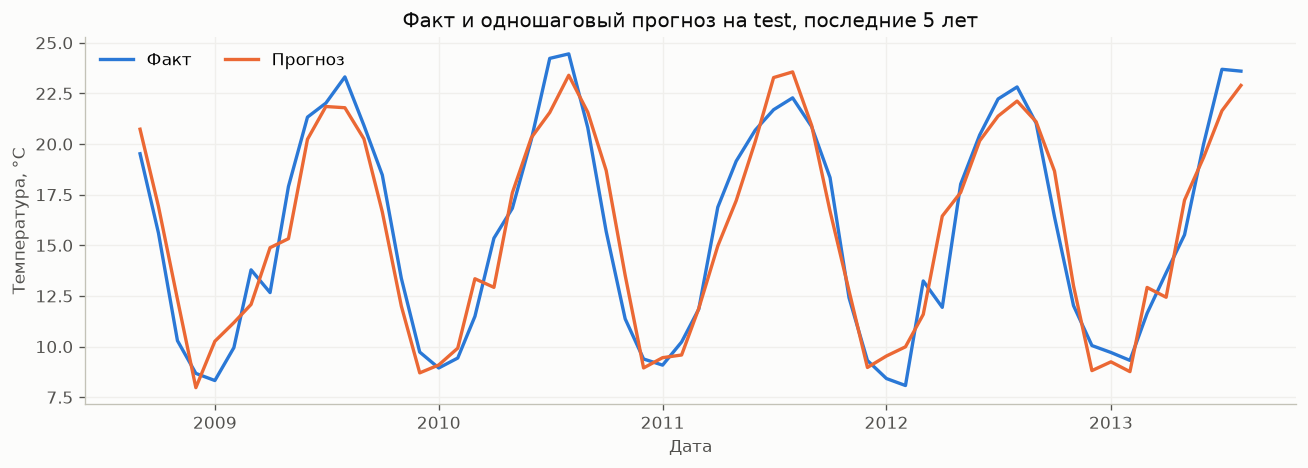

In [11]:
last_actual = y_test.iloc[-60:]
last_pred = y_pred.iloc[-60:]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(last_actual.index, last_actual, color=BLUE, linewidth=2, label='Факт')
ax.plot(last_pred.index, last_pred, color=ORANGE, linewidth=2, label='Прогноз')
ax.set_title('Факт и одношаговый прогноз на test, последние 5 лет')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.legend(loc='upper left', ncols=2)
fig.tight_layout()
plt.show()

**Вывод.** Модель обучена только на train, а самый большой коэффициент получил lag_12 (0.726), то есть температура того же месяца год назад. Прогноз одношаговый: lag_1 на test берёт факт предыдущего месяца, он известен к моменту прогноза, поэтому утечки нет.

## 6. Метрики и интерпретация

In [12]:
month_means = y_test.groupby(y_test.index.month).mean()
amplitude = month_means.max() - month_means.min()
print('Сезонная амплитуда на test, °C:', round(amplitude, 2))
print('Минимальная температура на test, °C:', round(y_test.min(), 2))

pd.DataFrame([{
    'MAE, °C': round(mean_absolute_error(y_test, y_pred), 3),
    'RMSE, °C': round(root_mean_squared_error(y_test, y_pred), 3),
    'MAPE, %': round(mean_absolute_percentage_error(y_test, y_pred) * 100, 2),
}])

Сезонная амплитуда на test, °C: 13.95
Минимальная температура на test, °C: 7.02


,"MAE, °C","RMSE, °C","MAPE, %"
0,1.14,1.411,8.41


**Вывод.** MAE 1.14 °C и RMSE 1.411 °C малы по сравнению с сезонной амплитудой 13.95 °C: MAE равна примерно 8% амплитуды, так что прогноз хорошо передаёт сезонный цикл. MAPE 8.41% здесь показателен, потому что температуры на test не опускаются ниже 7.02 °C и деление на значения около нуля ошибку не раздувает.